# LIBRAIRIE

In [74]:
import numpy as np
np.set_printoptions(threshold=10000, suppress=True)
import pandas as pd
import warnings
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc, accuracy_score, precision_score, recall_score
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler

from sklearn.decomposition import PCA

# CHARGEMENT DES DONNEES

In [30]:
# 1. Chargement des données avec pandas
df = pd.read_csv("credit_scoring.csv", sep=';')

In [31]:
# Afficher les premières lignes pour inspection
print("Premières lignes du dataset")
print(df.head())
print("\n")

Premières lignes du dataset
   Seniority  Home  Time   Age  Marital  Records  Job  Expenses  Income  \
0        9.0   1.0  60.0  30.0      0.0      1.0  1.0      73.0   129.0   
1       17.0   1.0  60.0  58.0      1.0      1.0  0.0      48.0   131.0   
2       10.0   0.0  36.0  46.0      0.0      2.0  1.0      90.0   200.0   
3        0.0   1.0  60.0  24.0      1.0      1.0  0.0      63.0   182.0   
4        0.0   1.0  36.0  26.0      1.0      1.0  0.0      46.0   107.0   

   Assets  Debt  Amount   Price  Status  
0     0.0   0.0   800.0   846.0       1  
1     0.0   0.0  1000.0  1658.0       1  
2  3000.0   0.0  2000.0  2985.0       0  
3  2500.0   0.0   900.0  1325.0       1  
4     0.0   0.0   310.0   910.0       1  




# TRANSFORMATION EN NUMPY

In [32]:
# 2. Transformation en numpy array
data_array = df.values
print(f" Transformation en numpu array\n {data_array}")
print(f"Type de data_array : {type(data_array)}")

 Transformation en numpu array
 [[   9.    1.   60. ...  800.  846.    1.]
 [  17.    1.   60. ... 1000. 1658.    1.]
 [  10.    0.   36. ... 2000. 2985.    0.]
 ...
 [   0.    0.   24. ...  500.  963.    0.]
 [   0.    1.   48. ...  550.  550.    1.]
 [   5.    0.   60. ... 1350. 1650.    1.]]
Type de data_array : <class 'numpy.ndarray'>


# SEPARATION DES X ET Y

In [33]:
# Séparation des caractéristiques (X) et de la variable cible (y)
X = data_array[:, :-1]  # Toutes les colonnes sauf la dernière
y = data_array[:, -1]   # Dernière colonne (status)

# DETAIL DU DATASET

In [ ]:
# Taille de l'échantillon
print(f"Shape du DataFrame original : {df.shape}")
print(f"Shape de X (caractéristiques) : {X.shape}")
print(f"Shape de y (target) : {y.shape}")
print(f"Nombre total d'exemples : {X.shape[0]}")
print(f"Nombre de caractéristiques : {X.shape[1]}")
print("\n")

print("\nPremières lignes de X:")
print(X[:3])
print("\nPremières valeurs de y:")
print(y[:3])

Shape du DataFrame original : (4375, 14)
Shape de X (caractéristiques) : (4375, 13)
Shape de y (target) : (4375,)
Nombre total d'exemples : 4375
Nombre de caractéristiques : 13




In [35]:
# Analyse des valeurs uniques et leurs counts
unique_values, counts = np.unique(y, return_counts=True)

print(f"Valeurs uniques dans 'status' : {unique_values}")
print(f"Counts correspondants : {counts}")
print("\n")

# Calcul des pourcentages
total_samples = len(y)
print(f"Nombre total d'échantillons : {total_samples}")

Valeurs uniques dans 'status' : [0. 1.]
Counts correspondants : [1216 3159]


Nombre total d'échantillons : 4375


# CLASSE NEGATIVE/POSITIVE

In [36]:
# Analyse détaillée pour chaque classe
for i, (value, count) in enumerate(zip(unique_values, counts)):
    percentage = (count / total_samples) * 100
    print(f"Classe {value} :")
    print(f"  - Nombre d'exemples : {count}")
    print(f"  - Pourcentage : {percentage:.2f}%")
    
    # Identification des classes positives et négatives
    if len(unique_values) == 2:
        if i == 0:
            print(f"  - Interprétation : Classe négative (mauvais crédit)")
        else:
            print(f"  - Interprétation : Classe positive (bon crédit)")
    print("")


Classe 0.0 :
  - Nombre d'exemples : 1216
  - Pourcentage : 27.79%
  - Interprétation : Classe négative (mauvais crédit)

Classe 1.0 :
  - Nombre d'exemples : 3159
  - Pourcentage : 72.21%
  - Interprétation : Classe positive (bon crédit)



# SEPARATION DES DONNEES EN TRAIN/TEST

In [46]:
# Séparation des données en train/test (50% chacune)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.5, 
    random_state=1,
)

print(f"Taille de l'ensemble d'apprentissage : {X_train.shape[0]} exemples")
print(f"Taille de l'ensemble de test : {X_test.shape[0]} exemples")
print(f"Proportion train/test : {X_train.shape[0]/len(X)*100:.1f}% / {X_test.shape[0]/len(X)*100:.1f}%")
print("\n")

Taille de l'ensemble d'apprentissage : 2187 exemples
Taille de l'ensemble de test : 2188 exemples
Proportion train/test : 50.0% / 50.0%




# LES ALGORITHMES / evaluation + test

In [49]:
# Dictionnaire des algorithmes
algorithms = {
    'CART': DecisionTreeClassifier(random_state=1),
    'KNN-5': KNeighborsClassifier(n_neighbors=5),
    'MLP': MLPClassifier(hidden_layer_sizes=(40, 20), random_state=1, max_iter=1000)
}

print("Algorithmes définis :")
for name, model in algorithms.items():
    print(f"- {name}")

Algorithmes définis :
- CART
- KNN-5
- MLP


In [50]:
def evaluate_model(model, X_test, y_test, model_name):
    """
    Évalue un modèle et retourne les métriques
    """
    # Prédictions
    y_pred = model.predict(X_test)
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    
    # Calcul des métriques
    acc = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    

    best_metric = recall  # Rappel choisi comme critère métier
    
    # Score final = moyenne entre accuracy et rappel
    final_score = (acc + best_metric) / 2
    
    # Matrice de confusion
    cm = confusion_matrix(y_test, y_pred)
    
    # Courbe ROC
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    roc_auc = auc(fpr, tpr)
    
    return {
        'accuracy': acc,
        'precision': precision,
        'recall': recall,
        'best_metric': best_metric,
        'final_score': final_score,
        'confusion_matrix': cm,
        'fpr': fpr,
        'tpr': tpr,
        'roc_auc': roc_auc,
        'y_pred': y_pred,
        'y_pred_proba': y_pred_proba
    }

In [51]:
def plot_roc_curves(results):
    """
    Affiche toutes les courbes ROC sur le même graphique
    """
    plt.figure(figsize=(10, 8))
    
    for name, result in results.items():
        metrics = result['metrics']
        plt.plot(metrics['fpr'], metrics['tpr'], 
                label=f'{name} (AUC = {metrics["roc_auc"]:.3f})', linewidth=2)
    
    # Courbe de référence
    plt.plot([0, 1], [0, 1], 'k--', label='Aléatoire (AUC = 0.500)', alpha=0.6)
    
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Taux de Faux Positifs (FPR)', fontsize=12)
    plt.ylabel('Taux de Vrais Positifs (TPR)', fontsize=12)
    plt.title('Courbes ROC - Comparaison des modèles', fontsize=14, fontweight='bold')
    plt.legend(loc="lower right")
    plt.grid(True, alpha=0.3)
    plt.show()

def plot_confusion_matrices(results):
    """
    Affiche les matrices de confusion côte à côte
    """
    fig, axes = plt.subplots(1, len(results), figsize=(15, 4))
    
    if len(results) == 1:
        axes = [axes]
    
    for idx, (name, result) in enumerate(results.items()):
        cm = result['metrics']['confusion_matrix']
        ax = axes[idx]
        
        # Utilisation de seaborn pour une meilleure visualisation
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                   cbar=False, square=True, annot_kws={'size': 14})
        
        ax.set_title(f'{name}\nAccuracy: {result["metrics"]["accuracy"]:.3f}', fontweight='bold')
        ax.set_ylabel('Vraie étiquette')
        ax.set_xlabel('Étiquette prédite')
        ax.set_xticklabels(['Négatif', 'Positif'])
        ax.set_yticklabels(['Négatif', 'Positif'], rotation=0)
    
    plt.tight_layout()
    plt.show()

In [52]:
def run_classifiers_train_test(X_train, X_test, y_train, y_test):
    """
    Entraîne et évalue tous les classifieurs du dictionnaire
    """
    results = {}
    best_model = None
    best_score = -1
    best_model_name = ""
    
    print("=== APPRENTISSAGE ET ÉVALUATION DES MODÈLES ===")
    print("=" * 60)
    
    for name, model in algorithms.items():
        print(f"\n {name}")
        print("-" * 30)
        
        # Entraînement du modèle
        model.fit(X_train, y_train)
        
        # Évaluation
        eval_results = evaluate_model(model, X_test, y_test, name)
        results[name] = {
            'model': model,
            'metrics': eval_results
        }
        
        # Affichage des résultats
        print(f"Accuracy:    {eval_results['accuracy']:.4f}")
        print(f"Precision:   {eval_results['precision']:.4f}")
        print(f"Recall:      {eval_results['recall']:.4f}")
        print(f"Score final: {eval_results['final_score']:.4f} (Accuracy + Recall)/2")
        print(f"AUC:         {eval_results['roc_auc']:.4f}")
        
        # Mise à jour du meilleur modèle
        if eval_results['final_score'] > best_score:
            best_score = eval_results['final_score']
            best_model = model
            best_model_name = name
    
    # Affichage comparatif
    print("\n" + "=" * 60)
    print("COMPARAISON DES MODÈLES")
    print("=" * 60)
    for name in results:
        score = results[name]['metrics']['final_score']
        print(f"{name:10} : {score:.4f}")
    
    print(f"\n MEILLEUR MODÈLE: {best_model_name} avec un score de {best_score:.4f}")
    
    return best_model, best_model_name, results

Début de l'apprentissage...
=== APPRENTISSAGE ET ÉVALUATION DES MODÈLES ===

 CART
------------------------------
Accuracy:    0.7271
Precision:   0.8194
Recall:      0.7992
Score final: 0.7632 (Accuracy + Recall)/2
AUC:         0.6687

 KNN-5
------------------------------
Accuracy:    0.7249
Precision:   0.7710
Recall:      0.8819
Score final: 0.8034 (Accuracy + Recall)/2
AUC:         0.6568

 MLP
------------------------------
Accuracy:    0.7367
Precision:   0.8051
Recall:      0.8396
Score final: 0.7882 (Accuracy + Recall)/2
AUC:         0.7242

COMPARAISON DES MODÈLES
CART       : 0.7632
KNN-5      : 0.8034
MLP        : 0.7882

 MEILLEUR MODÈLE: KNN-5 avec un score de 0.8034

VISUALISATIONS

Courbes ROC :


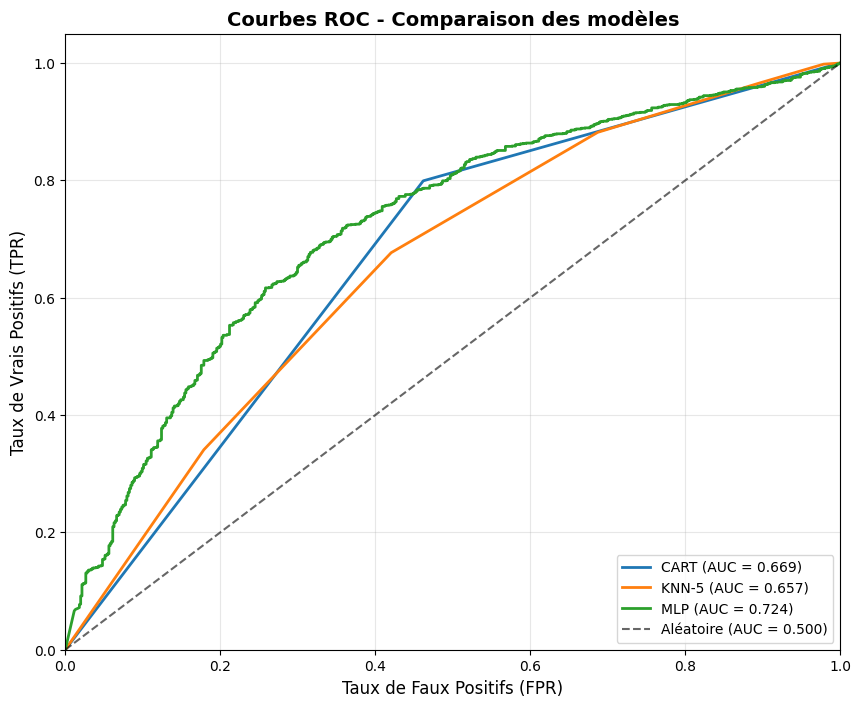


Matrices de confusion :


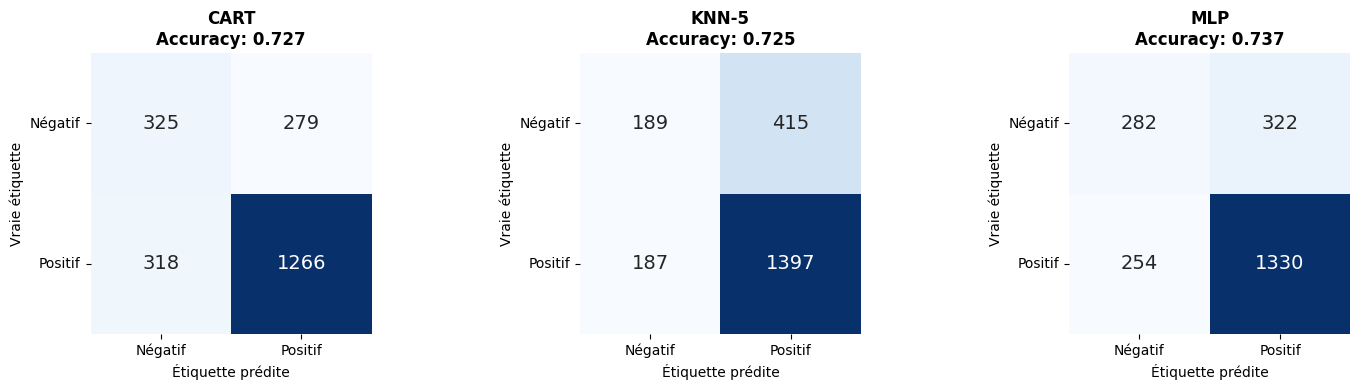


 MEILLEUR MODÈLE SÉLECTIONNÉ: KNN-5


In [54]:
# EXÉCUTION PRINCIPALE
print("Début de l'apprentissage...")
best_model, best_model_name, all_results = run_classifiers_train_test(
    X_train, X_test, y_train, y_test
)

# Affichage des visualisations
print("\n" + "=" * 60)
print("VISUALISATIONS")
print("=" * 60)

# Courbes ROC
print("\nCourbes ROC :")
plot_roc_curves(all_results)

# Matrices de confusion
print("\nMatrices de confusion :")
plot_confusion_matrices(all_results)

print(f"\n MEILLEUR MODÈLE SÉLECTIONNÉ: {best_model_name}")

# NORMALISATION (StandardScaler/MinMaxScaler)

In [70]:
def normalize_data(X_train, X_test, method='standard'):
    """
    Normalise les données d'entraînement et de test
    """
    if method == 'standard':
        scaler = StandardScaler()
    elif method == 'minmax': 
        scaler = MinMaxScaler()
    else:
        raise ValueError("Méthode doit être 'standard' ou 'minmax'")
    
    # Fit seulement sur le train, transform sur train et test
    X_train_normalized = scaler.fit_transform(X_train)
    X_test_normalized = scaler.transform(X_test)
    
    return X_train_normalized, X_test_normalized, scaler

# Normalisation des données
print("NORMALISATION DES DONNÉES")
X_train_std, X_test_std, scaler_std = normalize_data(X_train, X_test, method='standard')

print("Données normalisées avec StandardScaler")
print(f"Shape X_train normalisé: {X_train_std.shape}")
print(f"Shape X_test normalisé: {X_test_std.shape}")

# Statistiques avant/après normalisation
print("\nCOMPARAISON AVANT/APRÈS NORMALISATION")
print("Moyennes (avant normalisation):", np.mean(X_train, axis=0)[:5])  # 5 premières features
print("Moyennes (après normalisation):", np.mean(X_train_std, axis=0)[:5])
print("\nÉcart-types (avant normalisation):", np.std(X_train, axis=0)[:5])
print("Écart-types (après normalisation):", np.std(X_train_std, axis=0)[:5])

NORMALISATION DES DONNÉES
Données normalisées avec StandardScaler
Shape X_train normalisé: (2187, 13)
Shape X_test normalisé: (2188, 13)

COMPARAISON AVANT/APRÈS NORMALISATION
Moyennes (avant normalisation): [ 7.96844993  0.53680841 46.4170096  37.25788752  0.27343393]
Moyennes (après normalisation): [ 0.  0. -0. -0.  0.]

Écart-types (avant normalisation): [ 8.14171528  0.4986433  14.59622201 11.05319373  0.44572168]
Écart-types (après normalisation): [1. 1. 1. 1. 1.]


In [71]:
# Exécution des modèles sur données normalisées
print("=" * 70)
print("APPRENTISSAGE AVEC DONNÉES NORMALISÉES (StandardScaler)")
print("=" * 70)

best_model_std, best_model_name_std, results_std = run_classifiers_train_test(
    X_train_std, X_test_std, y_train, y_test
)

APPRENTISSAGE AVEC DONNÉES NORMALISÉES (StandardScaler)
=== APPRENTISSAGE ET ÉVALUATION DES MODÈLES ===

 CART
------------------------------
Accuracy:    0.7271
Precision:   0.8182
Recall:      0.8011
Score final: 0.7641 (Accuracy + Recall)/2
AUC:         0.6671

 KNN-5
------------------------------
Accuracy:    0.7527
Precision:   0.8106
Recall:      0.8592
Score final: 0.8060 (Accuracy + Recall)/2
AUC:         0.7539

 MLP
------------------------------
Accuracy:    0.7445
Precision:   0.8262
Recall:      0.8194
Score final: 0.7820 (Accuracy + Recall)/2
AUC:         0.7738

COMPARAISON DES MODÈLES
CART       : 0.7641
KNN-5      : 0.8060
MLP        : 0.7820

 MEILLEUR MODÈLE: KNN-5 avec un score de 0.8060


In [72]:
def compare_results_original_vs_normalized(results_original, results_normalized):
    """
    Compare les résultats avant et après normalisation
    """
    print("=" * 80)
    print("COMPARAISON DÉTAILLÉE : ORIGINAL vs NORMALISÉ")
    print("=" * 80)
    
    comparison_data = []
    
    for model_name in results_original.keys():
        if model_name in results_normalized:
            # Résultats originaux
            orig = results_original[model_name]['metrics']
            # Résultats normalisés
            norm = results_normalized[model_name]['metrics']
            
            # Calcul des différences
            diff_accuracy = norm['accuracy'] - orig['accuracy']
            diff_recall = norm['recall'] - orig['recall']
            diff_final = norm['final_score'] - orig['final_score']
            diff_auc = norm['roc_auc'] - orig['roc_auc']
            
            comparison_data.append({
                'Modèle': model_name,
                'Accuracy_orig': orig['accuracy'],
                'Accuracy_norm': norm['accuracy'],
                'Diff_accuracy': diff_accuracy,

                'Recall_orig': orig['recall'],
                'Recall_norm': norm['recall'],
                'Diff_recall': diff_recall,

                'Final_orig': orig['final_score'],
                'Final_norm': norm['final_score'],
                'Diff_final': diff_final,

                'AUC_orig': orig['roc_auc'],
                'AUC_norm': norm['roc_auc'],
                'Diff_auc': diff_auc
            })
            
            # Affichage détaillé par modèle
            print(f"\n {model_name}")
            print("-" * 40)
            print(f"Accuracy:  {orig['accuracy']:.4f} → {norm['accuracy']:.4f} ({diff_accuracy:+.4f})")
            print(f"Recall:    {orig['recall']:.4f} → {norm['recall']:.4f} ({diff_recall:+.4f})")
            print(f"Score final: {orig['final_score']:.4f} → {norm['final_score']:.4f} ({diff_final:+.4f})")
            print(f"AUC:       {orig['roc_auc']:.4f} → {norm['roc_auc']:.4f} ({diff_auc:+.4f})")
            
            # Interprétation
            if diff_final > 0:
                print("Amélioration avec normalisation")
            elif diff_final < 0:
                print("Dégradation avec normalisation")
            else:
                print("Pas de changement")
    
    return comparison_data

# Exécution de la comparaison
comparison = compare_results_original_vs_normalized(all_results, results_std)

COMPARAISON DÉTAILLÉE : ORIGINAL vs NORMALISÉ

 CART
----------------------------------------
Accuracy:  0.7271 → 0.7271 (+0.0000)
Recall:    0.7992 → 0.8011 (+0.0019)
Score final: 0.7632 → 0.7641 (+0.0009)
AUC:       0.6687 → 0.6671 (-0.0015)
Amélioration avec normalisation

 KNN-5
----------------------------------------
Accuracy:  0.7249 → 0.7527 (+0.0279)
Recall:    0.8819 → 0.8592 (-0.0227)
Score final: 0.8034 → 0.8060 (+0.0026)
AUC:       0.6568 → 0.7539 (+0.0972)
Amélioration avec normalisation

 MLP
----------------------------------------
Accuracy:  0.7367 → 0.7445 (+0.0078)
Recall:    0.8396 → 0.8194 (-0.0202)
Score final: 0.7882 → 0.7820 (-0.0062)
AUC:       0.7242 → 0.7738 (+0.0496)
Dégradation avec normalisation


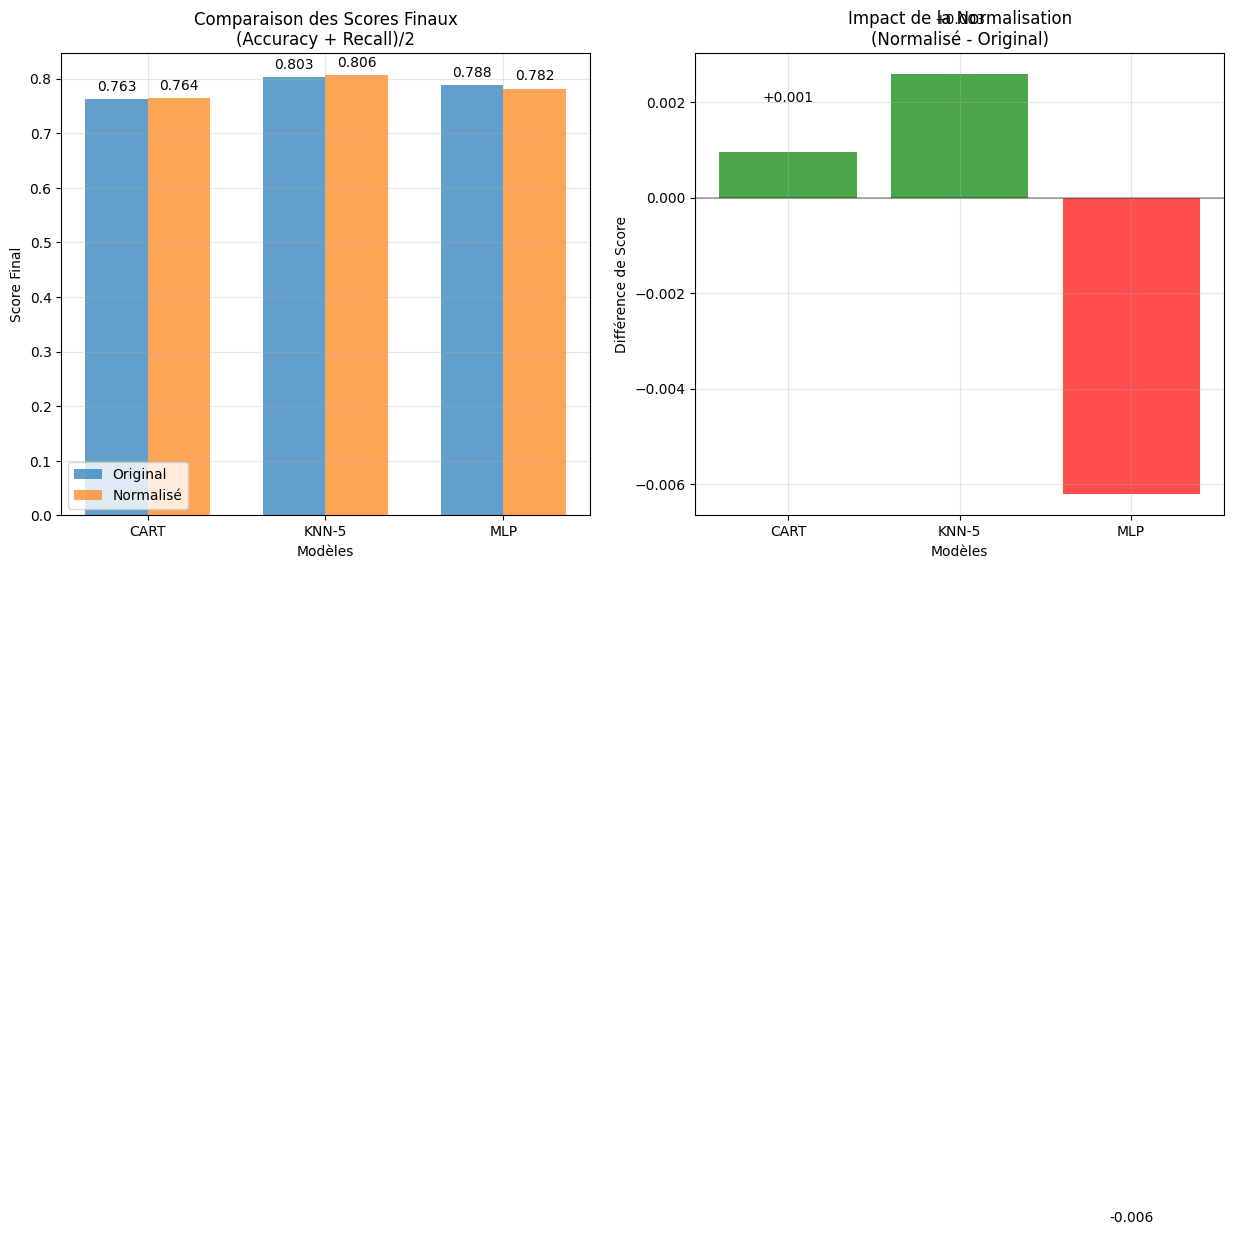

In [73]:
# Visualisation des comparaisons
def plot_comparison(comparison_data):
    """
    Visualise la comparaison avant/après normalisation
    """
    models = [item['Modèle'] for item in comparison_data]
    final_original = [item['Final_orig'] for item in comparison_data]
    final_normalized = [item['Final_norm'] for item in comparison_data]
    
    x = np.arange(len(models))
    width = 0.35
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    
    # Graphique 1: Scores finaux
    bars1 = ax1.bar(x - width/2, final_original, width, label='Original', alpha=0.7)
    bars2 = ax1.bar(x + width/2, final_normalized, width, label='Normalisé', alpha=0.7)
    
    ax1.set_xlabel('Modèles')
    ax1.set_ylabel('Score Final')
    ax1.set_title('Comparaison des Scores Finaux\n(Accuracy + Recall)/2')
    ax1.set_xticks(x)
    ax1.set_xticklabels(models)
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # Ajouter les valeurs sur les barres
    for bar in bars1:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{height:.3f}', ha='center', va='bottom')
    
    for bar in bars2:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{height:.3f}', ha='center', va='bottom')
    
    # Graphique 2: Différences de performance
    differences = [item['Diff_final'] for item in comparison_data]
    colors = ['green' if diff > 0 else 'red' for diff in differences]
    
    bars = ax2.bar(models, differences, color=colors, alpha=0.7)
    ax2.set_xlabel('Modèles')
    ax2.set_ylabel('Différence de Score')
    ax2.set_title('Impact de la Normalisation\n(Normalisé - Original)')
    ax2.axhline(y=0, color='black', linestyle='-', alpha=0.3)
    ax2.grid(True, alpha=0.3)
    
    # Ajouter les valeurs sur les barres
    for bar, diff in zip(bars, differences):
        height = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2., height + (0.001 if height >= 0 else -0.015),
                f'{height:+.3f}', ha='center', va='bottom' if height >= 0 else 'top')
    
    plt.tight_layout()
    plt.show()

# Affichage de la visualisation
plot_comparison(comparison)

# PCA

In [76]:
def apply_pca_and_concat(X_train, X_test, n_components=3):
    """
    Applique l'ACP et concatène les composantes aux données originales
    """
    # Application de l'ACP
    pca = PCA(n_components=n_components, random_state=1)
    
    # Fit seulement sur le train
    X_train_pca = pca.fit_transform(X_train)
    X_test_pca = pca.transform(X_test)
    
    # Concaténation avec les données originales
    X_train_combined = np.concatenate([X_train, X_train_pca], axis=1)
    X_test_combined = np.concatenate([X_test, X_test_pca], axis=1)
    
    return X_train_combined, X_test_combined, pca, X_train_pca, X_test_pca

print("APPLICATION DE L'ACP")
# Application sur les données normalisées
X_train_pca_combined, X_test_pca_combined, pca, X_train_pca, X_test_pca = apply_pca_and_concat(
    X_train_std, X_test_std, n_components=3
)

print(f"Shape données originales: {X_train_std.shape}")
print(f"Shape composantes ACP: {X_train_pca.shape}")
print(f"Shape données combinées: {X_train_pca_combined.shape}")

# Analyse de l'ACP
print(f"\nANALYSE DE L'ACP")
print(f"Variance expliquée par chaque composante: {pca.explained_variance_ratio_}")
print(f"Variance cumulative: {np.cumsum(pca.explained_variance_ratio_)}")
print(f"Total variance expliquée: {np.sum(pca.explained_variance_ratio_):.3f}")

APPLICATION DE L'ACP
Shape données originales: (2187, 13)
Shape composantes ACP: (2187, 3)
Shape données combinées: (2187, 16)

ANALYSE DE L'ACP
Variance expliquée par chaque composante: [0.18820572 0.14667046 0.10648009]
Variance cumulative: [0.18820572 0.33487618 0.44135627]
Total variance expliquée: 0.441


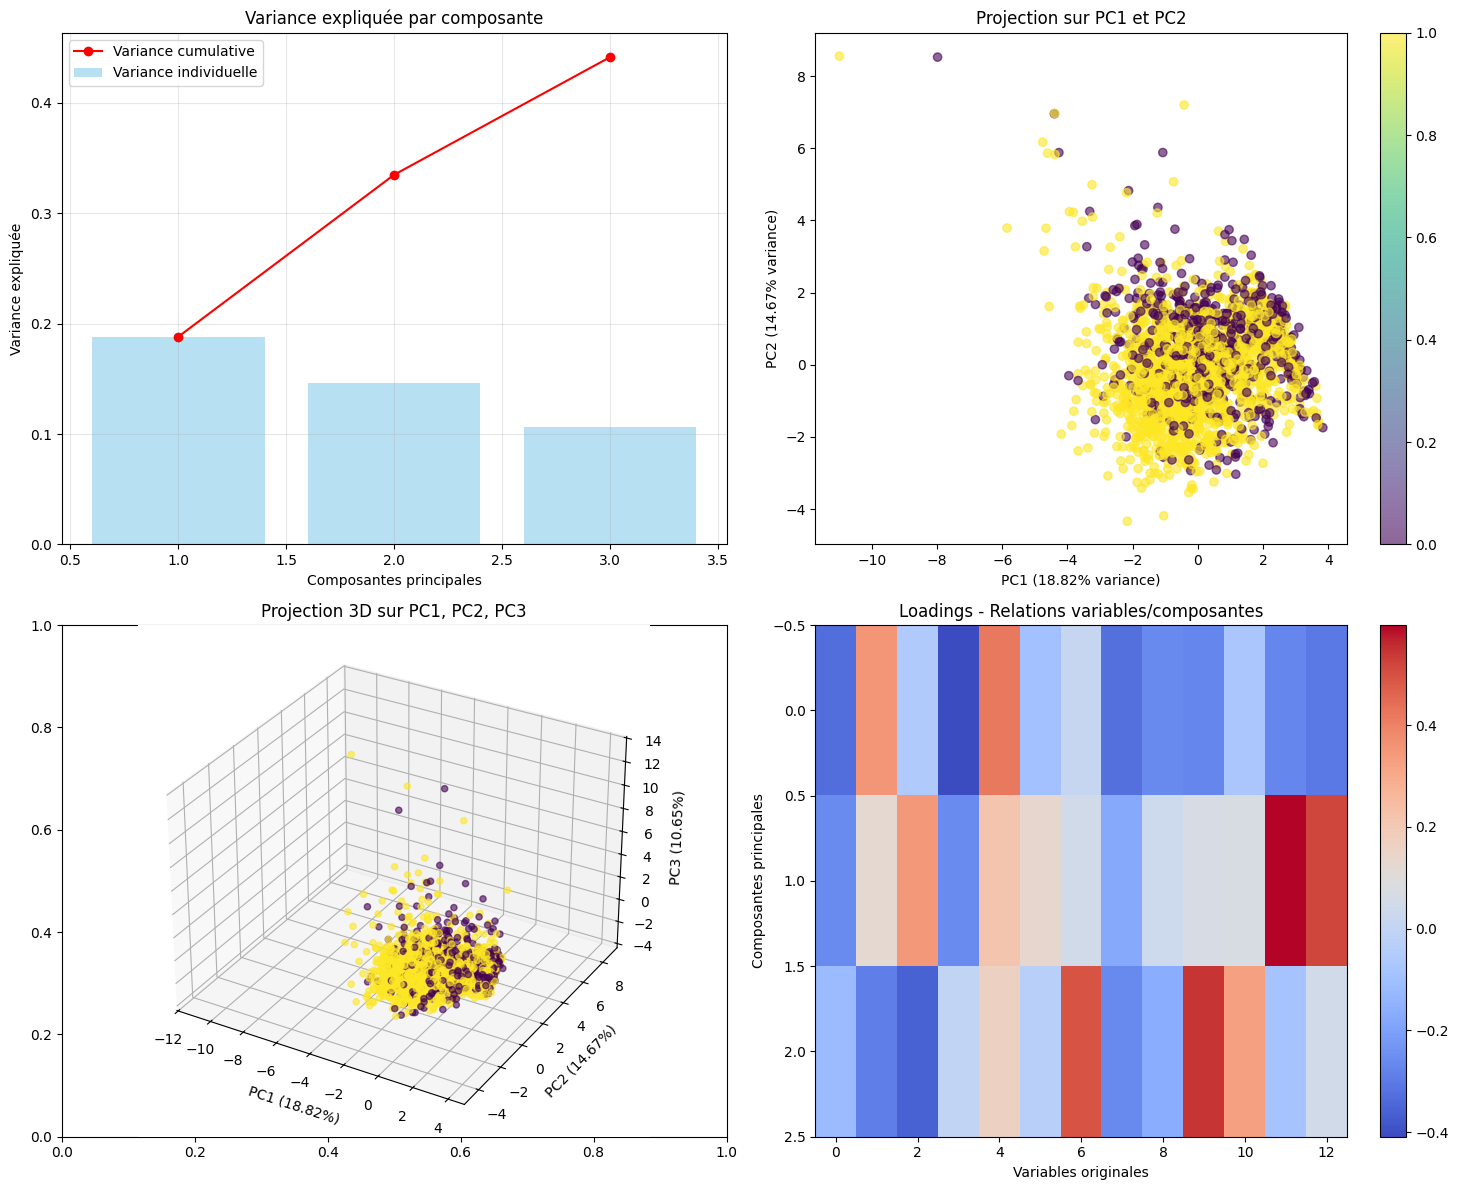

In [77]:
def plot_pca_analysis(pca, X_train_pca, y_train):
    """
    Visualise les résultats de l'ACP
    """
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    
    # 1. Variance expliquée
    explained_variance = pca.explained_variance_ratio_
    cumulative_variance = np.cumsum(explained_variance)
    
    axes[0, 0].bar(range(1, len(explained_variance) + 1), explained_variance, alpha=0.6, color='skyblue', label='Variance individuelle')
    axes[0, 0].plot(range(1, len(cumulative_variance) + 1), cumulative_variance, 'ro-', label='Variance cumulative')
    axes[0, 0].set_xlabel('Composantes principales')
    axes[0, 0].set_ylabel('Variance expliquée')
    axes[0, 0].set_title('Variance expliquée par composante')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    
    # 2. Projection sur les 2 premières composantes
    scatter = axes[0, 1].scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, cmap='viridis', alpha=0.6)
    axes[0, 1].set_xlabel(f'PC1 ({explained_variance[0]:.2%} variance)')
    axes[0, 1].set_ylabel(f'PC2 ({explained_variance[1]:.2%} variance)')
    axes[0, 1].set_title('Projection sur PC1 et PC2')
    plt.colorbar(scatter, ax=axes[0, 1])
    
    # 3. Projection 3D (si 3 composantes)
    if X_train_pca.shape[1] >= 3:
        ax3d = fig.add_subplot(2, 2, 3, projection='3d')
        scatter3d = ax3d.scatter(X_train_pca[:, 0], X_train_pca[:, 1], X_train_pca[:, 2], 
                                c=y_train, cmap='viridis', alpha=0.6)
        ax3d.set_xlabel(f'PC1 ({explained_variance[0]:.2%})')
        ax3d.set_ylabel(f'PC2 ({explained_variance[1]:.2%})')
        ax3d.set_zlabel(f'PC3 ({explained_variance[2]:.2%})')
        ax3d.set_title('Projection 3D sur PC1, PC2, PC3')
    
    # 4. Heatmap des loadings (premières composantes)
    if hasattr(pca, 'components_'):
        im = axes[1, 1].imshow(pca.components_[:3, :], cmap='coolwarm', aspect='auto')
        axes[1, 1].set_xlabel('Variables originales')
        axes[1, 1].set_ylabel('Composantes principales')
        axes[1, 1].set_title('Loadings - Relations variables/composantes')
        plt.colorbar(im, ax=axes[1, 1])
    
    plt.tight_layout()
    plt.show()

# Visualisation
plot_pca_analysis(pca, X_train_pca, y_train)

In [78]:
# Exécution des modèles sur données avec ACP
print("=" * 80)
print("APPRENTISSAGE AVEC DONNÉES NORMALISÉES + ACP")
print("=" * 80)

best_model_pca, best_model_name_pca, results_pca = run_classifiers_train_test(
    X_train_pca_combined, X_test_pca_combined, y_train, y_test
)

APPRENTISSAGE AVEC DONNÉES NORMALISÉES + ACP
=== APPRENTISSAGE ET ÉVALUATION DES MODÈLES ===

 CART
------------------------------
Accuracy:    0.7258
Precision:   0.8233
Recall:      0.7910
Score final: 0.7584 (Accuracy + Recall)/2
AUC:         0.6728

 KNN-5
------------------------------
Accuracy:    0.7564
Precision:   0.8104
Recall:      0.8662
Score final: 0.8113 (Accuracy + Recall)/2
AUC:         0.7555

 MLP
------------------------------
Accuracy:    0.7500
Precision:   0.8222
Recall:      0.8352
Score final: 0.7926 (Accuracy + Recall)/2
AUC:         0.7745

COMPARAISON DES MODÈLES
CART       : 0.7584
KNN-5      : 0.8113
MLP        : 0.7926

 MEILLEUR MODÈLE: KNN-5 avec un score de 0.8113


## COMPARAISON

In [79]:
def comprehensive_comparison(all_strategies):
    """
    Compare toutes les stratégies de préparation des données
    """
    print("=" * 100)
    print("COMPARAISON COMPLÈTE DES STRATÉGIES DE PRÉPARATION DES DONNÉES")
    print("=" * 100)
    
    strategies = list(all_strategies.keys())
    models = list(all_strategies[strategies[0]].keys())
    
    # Tableau de comparaison
    comparison_table = []
    
    for strategy in strategies:
        print(f"\nSTRATÉGIE: {strategy}")
        print("-" * 50)
        
        for model in models:
            if model in all_strategies[strategy]:
                metrics = all_strategies[strategy][model]['metrics']
                comparison_table.append({
                    'Stratégie': strategy,
                    'Modèle': model,
                    'Accuracy': metrics['accuracy'],
                    'Recall': metrics['recall'],
                    'Final_Score': metrics['final_score'],
                    'AUC': metrics['roc_auc']
                })
                
                print(f"{model:8} | Accuracy: {metrics['accuracy']:.4f} | Recall: {metrics['recall']:.4f} | "
                      f"Final: {metrics['final_score']:.4f} | AUC: {metrics['roc_auc']:.4f}")
    
    return pd.DataFrame(comparison_table)

# Collecte de toutes les stratégies
all_strategies = {
    'Original': all_results,
    'Normalisé': results_std,
    'Normalisé + ACP': results_pca
}

# Comparaison complète
comparison_df = comprehensive_comparison(all_strategies)

COMPARAISON COMPLÈTE DES STRATÉGIES DE PRÉPARATION DES DONNÉES

STRATÉGIE: Original
--------------------------------------------------
CART     | Accuracy: 0.7271 | Recall: 0.7992 | Final: 0.7632 | AUC: 0.6687
KNN-5    | Accuracy: 0.7249 | Recall: 0.8819 | Final: 0.8034 | AUC: 0.6568
MLP      | Accuracy: 0.7367 | Recall: 0.8396 | Final: 0.7882 | AUC: 0.7242

STRATÉGIE: Normalisé
--------------------------------------------------
CART     | Accuracy: 0.7271 | Recall: 0.8011 | Final: 0.7641 | AUC: 0.6671
KNN-5    | Accuracy: 0.7527 | Recall: 0.8592 | Final: 0.8060 | AUC: 0.7539
MLP      | Accuracy: 0.7445 | Recall: 0.8194 | Final: 0.7820 | AUC: 0.7738

STRATÉGIE: Normalisé + ACP
--------------------------------------------------
CART     | Accuracy: 0.7258 | Recall: 0.7910 | Final: 0.7584 | AUC: 0.6728
KNN-5    | Accuracy: 0.7564 | Recall: 0.8662 | Final: 0.8113 | AUC: 0.7555
MLP      | Accuracy: 0.7500 | Recall: 0.8352 | Final: 0.7926 | AUC: 0.7745


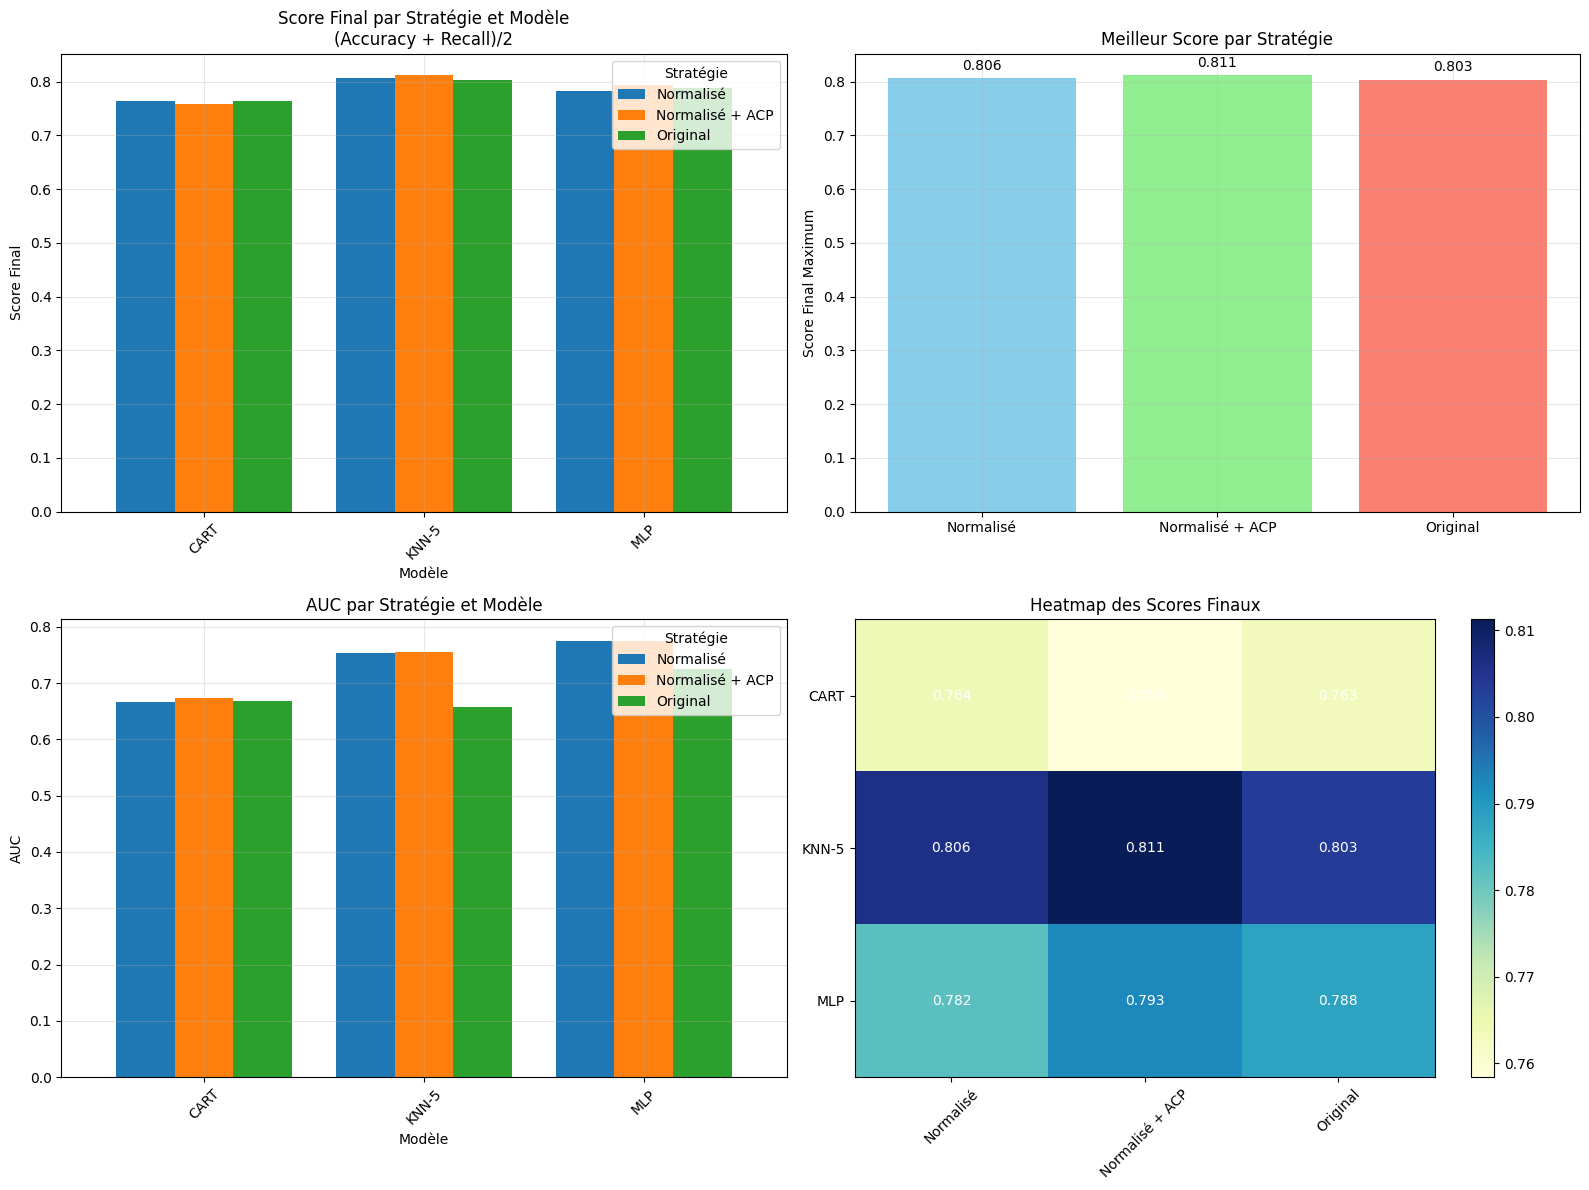

In [80]:
def plot_global_comparison(comparison_df):
    """
    Visualise la comparaison globale des stratégies
    """
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    
    # 1. Scores finaux par stratégie et modèle
    pivot_final = comparison_df.pivot(index='Modèle', columns='Stratégie', values='Final_Score')
    pivot_final.plot(kind='bar', ax=axes[0, 0], width=0.8)
    axes[0, 0].set_title('Score Final par Stratégie et Modèle\n(Accuracy + Recall)/2')
    axes[0, 0].set_ylabel('Score Final')
    axes[0, 0].legend(title='Stratégie')
    axes[0, 0].tick_params(axis='x', rotation=45)
    axes[0, 0].grid(True, alpha=0.3)
    
    # 2. Meilleur score par stratégie
    best_by_strategy = comparison_df.groupby('Stratégie')['Final_Score'].max()
    axes[0, 1].bar(best_by_strategy.index, best_by_strategy.values, color=['skyblue', 'lightgreen', 'salmon'])
    axes[0, 1].set_title('Meilleur Score par Stratégie')
    axes[0, 1].set_ylabel('Score Final Maximum')
    for i, v in enumerate(best_by_strategy.values):
        axes[0, 1].text(i, v + 0.01, f'{v:.3f}', ha='center', va='bottom')
    axes[0, 1].grid(True, alpha=0.3)
    
    # 3. AUC par stratégie et modèle
    pivot_auc = comparison_df.pivot(index='Modèle', columns='Stratégie', values='AUC')
    pivot_auc.plot(kind='bar', ax=axes[1, 0], width=0.8)
    axes[1, 0].set_title('AUC par Stratégie et Modèle')
    axes[1, 0].set_ylabel('AUC')
    axes[1, 0].legend(title='Stratégie')
    axes[1, 0].tick_params(axis='x', rotation=45)
    axes[1, 0].grid(True, alpha=0.3)
    
    # 4. Heatmap des performances
    heatmap_data = comparison_df.pivot(index='Modèle', columns='Stratégie', values='Final_Score')
    im = axes[1, 1].imshow(heatmap_data.values, cmap='YlGnBu', aspect='auto')
    axes[1, 1].set_xticks(range(len(heatmap_data.columns)))
    axes[1, 1].set_xticklabels(heatmap_data.columns, rotation=45)
    axes[1, 1].set_yticks(range(len(heatmap_data.index)))
    axes[1, 1].set_yticklabels(heatmap_data.index)
    axes[1, 1].set_title('Heatmap des Scores Finaux')
    
    # Ajouter les valeurs dans la heatmap
    for i in range(len(heatmap_data.index)):
        for j in range(len(heatmap_data.columns)):
            axes[1, 1].text(j, i, f'{heatmap_data.iloc[i, j]:.3f}', 
                           ha='center', va='center', color='black' if heatmap_data.iloc[i, j] < 0.7 else 'white')
    
    plt.colorbar(im, ax=axes[1, 1])
    plt.tight_layout()
    plt.show()

# Affichage de la comparaison globale
plot_global_comparison(comparison_df)

In [81]:
print("=" * 100)
print("CONCLUSIONS ET RECOMMANDATIONS FINALES")
print("=" * 100)

# Meilleur modèle global
best_overall = comparison_df.loc[comparison_df['Final_Score'].idxmax()]
print(f"\nMEILLEUR RÉSULTAT GLOBAL:")
print(f"  Modèle: {best_overall['Modèle']}")
print(f"  Stratégie: {best_overall['Stratégie']}")
print(f"  Score final: {best_overall['Final_Score']:.4f}")
print(f"  AUC: {best_overall['AUC']:.4f}")

# Analyse par stratégie
print(f"\nANALYSE PAR STRATÉGIE:")

for strategy in all_strategies.keys():
    strategy_scores = comparison_df[comparison_df['Stratégie'] == strategy]['Final_Score']
    best_model_strategy = comparison_df[comparison_df['Stratégie'] == strategy].loc[
        comparison_df[comparison_df['Stratégie'] == strategy]['Final_Score'].idxmax()
    ]
    
    print(f"\n{strategy}:")
    print(f"  Score moyen: {strategy_scores.mean():.4f}")
    print(f"  Meilleur modèle: {best_model_strategy['Modèle']} ({best_model_strategy['Final_Score']:.4f})")
    print(f"  Écart-type: {strategy_scores.std():.4f}")

# Recommandations
print(f"\nRECOMMANDATIONS POUR LA SUITE:")
print(f"1. MEILLEUR ALGORITHME: {best_overall['Modèle']}")
print(f"2. MEILLEURE STRATÉGIE: {best_overall['Stratégie']}")

# Décision sur la normalisation
original_mean = comparison_df[comparison_df['Stratégie'] == 'Original']['Final_Score'].mean()
normalized_mean = comparison_df[comparison_df['Stratégie'] == 'Normalisé']['Final_Score'].mean()

if normalized_mean > original_mean:
    print("3. NORMALISATION: RECOMMANDÉE (améliore les performances)")
else:
    print("3. NORMALISATION: NON NÉCESSAIRE (pas d'amélioration significative)")

# Décision sur l'ACP
pca_mean = comparison_df[comparison_df['Stratégie'] == 'Normalisé + ACP']['Final_Score'].mean()
if pca_mean > normalized_mean and pca_mean > original_mean:
    print("4. ACP: RECOMMANDÉE (apporte une valeur ajoutée)")
else:
    print("4. ACP: NON NÉCESSAIRE (pas d'amélioration significative)")

print(f"\nSTRATÉGIE FINALE CHOISIE: {best_overall['Stratégie']} avec {best_overall['Modèle']}")

CONCLUSIONS ET RECOMMANDATIONS FINALES

MEILLEUR RÉSULTAT GLOBAL:
  Modèle: KNN-5
  Stratégie: Normalisé + ACP
  Score final: 0.8113
  AUC: 0.7555

ANALYSE PAR STRATÉGIE:

Original:
  Score moyen: 0.7849
  Meilleur modèle: KNN-5 (0.8034)
  Écart-type: 0.0203

Normalisé:
  Score moyen: 0.7840
  Meilleur modèle: KNN-5 (0.8060)
  Écart-type: 0.0210

Normalisé + ACP:
  Score moyen: 0.7874
  Meilleur modèle: KNN-5 (0.8113)
  Écart-type: 0.0268

RECOMMANDATIONS POUR LA SUITE:
1. MEILLEUR ALGORITHME: KNN-5
2. MEILLEURE STRATÉGIE: Normalisé + ACP
3. NORMALISATION: NON NÉCESSAIRE (pas d'amélioration significative)
4. ACP: RECOMMANDÉE (apporte une valeur ajoutée)

STRATÉGIE FINALE CHOISIE: Normalisé + ACP avec KNN-5
